# Predicción de la volatilidad mensual del S&P 500 y asignación dinámica entre acciones y bonos

**Finanzas Quant — Ciencia de Datos, FCEN-UBA**

**Pregunta de investigación.** ¿Un modelo de Machine Learning puede predecir la volatilidad mensual futura del S&P 500 mejor que una regla simple basada en la volatilidad del mes anterior? Si la mejora existe, ¿permite construir un portfolio entre acciones (SPY) y bonos (IEF) con una relación riesgo-retorno más favorable?

**Idea central.** No intentamos adivinar si el mercado sube o baja. Estimamos *cuán variable* puede ser el mes siguiente, y usamos esa estimación para decidir cuánto invertir en acciones.

La conclusión se separa en tres niveles: **predicción** (¿el modelo reduce el error fuera de muestra?), **decisión** (¿la regla mejora Sharpe o drawdown?) y **robustez** (¿se mantiene al cambiar la volatilidad objetivo y los costos?).

## 1. Librerías y parámetros reproducibles

In [52]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [53]:
# Parámetros del trabajo (todos fijados ANTES de mirar resultados)
FECHA_INICIO = "2003-01-01"
RANDOM_STATE = 42
TRAIN_SIZE_INICIAL = 120      # 10 años de meses para el primer entrenamiento
VOL_OBJETIVO = 0.12           # caso base σ*
VOL_OBJETIVO_SENS = [0.10, 0.12, 0.15]
COSTO_TRANSACCION = 0.001     # 0,10% por unidad de turnover
COSTOS_SENS = [0.0, 0.001, 0.0025]

# Hiperparámetros del Random Forest: fijados a priori, sin optimizar contra el test
RF_PARAMS = dict(n_estimators=300, max_depth=5, min_samples_leaf=5,
                 random_state=RANDOM_STATE, n_jobs=-1)

np.random.seed(RANDOM_STATE)

In [103]:
# Estilo común de los gráficos de resultados (solo apariencia; no cambia ningún cálculo).
# Un color fijo por modelo, el mismo en todos los gráficos. Se aplica con plt.rc_context(ESTILO),
# así no se modifica el estilo de los gráficos de las secciones anteriores.
from matplotlib.ticker import FixedLocator, FuncFormatter

COLOR_MODELO = {"Naive": "#A51DC7", "HAR": "#4C9F70", "HAR_VIX": "#2E75B6", "Random_Forest": "#D9731A"}
NOMBRE_MODELO = {"Naive": "Naive", "HAR": "HAR", "HAR_VIX": "HAR + VIX", "Random_Forest": "Random Forest"}
COLOR_ESTRATEGIA = {"SPY": "#1F2933", "60_40": "#8E6BBF"}
NOMBRE_ESTRATEGIA = {"SPY": "SPY", "60_40": "60/40"}
for _m in COLOR_MODELO:
    COLOR_ESTRATEGIA[f"VolTarget_{_m}"] = COLOR_MODELO[_m]
    NOMBRE_ESTRATEGIA[f"VolTarget_{_m}"] = f"VolTarget {NOMBRE_MODELO[_m]}"

TINTA, SUAVE, GRILLA, LINEA_SIGMA = "#1F2933", "#6B7785", "#E6ECF2", "#9FB3C8"
ESTILO = {"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
          "axes.edgecolor": "#B7C8DB", "axes.labelcolor": TINTA, "axes.titleweight": "bold",
          "xtick.color": SUAVE, "ytick.color": SUAVE}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
pct0 = FuncFormatter(lambda v, _: f"{v:.0%}")


def mes_de_retorno(indice):
    # La fecha del índice es la fecha de DECISIÓN (cierre del mes t). Lo que se mide (volatilidad
    # real, retorno de la cartera) ocurre en t+1. En los gráficos con fecha se muestra ese mes.
    return indice + pd.offsets.MonthEnd(1)


def etiqueta_mes(fecha):
    return f"{MESES[fecha.month - 1]} {fecha.year}"


def ticks_log(lo, hi):
    return [t for t in (0.03, 0.05, 0.10, 0.20, 0.40, 0.80) if lo <= t <= hi]

## 2. Descarga de datos

In [54]:
tickers = ["SPY", "IEF", "^VIX"]

datos_yahoo = yf.download(
    tickers,
    start=FECHA_INICIO,
    auto_adjust=True,
    progress=False
)

datos_yahoo.head()

Price           Close                             High                              Low                             Open                          Volume                 
Ticker            IEF        SPY       ^VIX        IEF        SPY       ^VIX        IEF        SPY       ^VIX        IEF        SPY       ^VIX       IEF         SPY ^VIX
Date                                                                                                                                                                     
2003-01-02  42.350929  59.182018  25.389999  42.825434  59.331486  28.740000  42.325954  57.537894  25.320000  42.755507  57.739346  28.740000  106700.0  44516300.0    0
2003-01-03  42.420895  59.363995  24.680000  42.420895  59.383489  25.549999  42.256065  58.811621  24.680000  42.306012  59.078063  25.549999  518400.0  32222600.0    0
2003-01-06  42.315987  60.410271  24.910000  42.355946  60.754692  25.420000  42.211096  59.247034  24.290001  42.355946  59.292524  25.320000  214500.0  40984500.0    0
2003-01-07  42.450836  60.260792  25.129999  42.475812  60.676697  25.690001  42.295998  59.916366  24.910000  42.315978  60.371265  25.129999  101700.0  38640400.0    0
2003-01-08  42.550724  59.389977  25.530001  42.605667  60.046328  25.760000  42.515761  59.169029  25.070000  42.540732  59.916355  25.620001  162600.0  38702200.0    0

In [55]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3"
dtb3 = pd.read_csv(url)
dtb3.head()

,observation_date,DTB3
0,1954-01-04,1.33
1,1954-01-05,1.28
2,1954-01-06,1.28
3,1954-01-07,1.31
4,1954-01-08,1.31


## 3. Limpieza y control de calidad

In [56]:
dtb3["observation_date"] = pd.to_datetime(dtb3["observation_date"])
dtb3 = dtb3.rename(columns={"observation_date": "Date", "DTB3": "RF_3M"})
dtb3 = dtb3[dtb3["Date"] >= FECHA_INICIO].copy()

print("Faltantes en DTB3 desde", FECHA_INICIO, ":", dtb3["RF_3M"].isna().sum())
dtb3[dtb3["RF_3M"].isna()].head(10)

Faltantes en DTB3 desde 2003-01-01 : 255


,Date,RF_3M
12782,2003-01-01,NaN
12795,2003-01-20,NaN
12815,2003-02-17,NaN
12859,2003-04-18,NaN
12885,2003-05-26,NaN
12914,2003-07-04,NaN
12955,2003-09-01,NaN
12985,2003-10-13,NaN
13006,2003-11-11,NaN
13018,2003-11-27,NaN


En general los días que faltan son feriados. Como después vamos a trabajar con frecuencia mensual (último valor disponible de cada mes), esos faltantes no afectan el análisis.

In [57]:
datos_yahoo.info()
datos_yahoo.isna().sum()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5980 entries, 2003-01-02 to 2026-10-06
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, IEF)    5978 non-null   float64
 1   (Close, SPY)    5978 non-null   float64
 2   (Close, ^VIX)   5980 non-null   float64
 3   (High, IEF)     5978 non-null   float64
 4   (High, SPY)     5978 non-null   float64
 5   (High, ^VIX)    5980 non-null   float64
 6   (Low, IEF)      5978 non-null   float64
 7   (Low, SPY)      5978 non-null   float64
 8   (Low, ^VIX)     5980 non-null   float64
 9   (Open, IEF)     5978 non-null   float64
 10  (Open, SPY)     5978 non-null   float64
 11  (Open, ^VIX)    5980 non-null   float64
 12  (Volume, IEF)   5978 non-null   float64
 13  (Volume, SPY)   5978 non-null   float64
 14  (Volume, ^VIX)  5980 non-null   int64  
dtypes: float64(14), int64(1)
memory usage: 747.5 KB


Price   Ticker
Close   IEF       2
        SPY       2
        ^VIX      0
High    IEF       2
        SPY       2
        ^VIX      0
Low     IEF       2
        SPY       2
        ^VIX      0
Open    IEF       2
        SPY       2
        ^VIX      0
Volume  IEF       2
        SPY       2
        ^VIX      0
dtype: int64

In [58]:
close = datos_yahoo["Close"][["SPY", "IEF", "^VIX"]].copy()

print("Filas con faltantes en SPY o IEF:")
print(close[close[["SPY", "IEF"]].isna().any(axis=1)])

close = close.dropna()
close.isna().sum()

Filas con faltantes en SPY o IEF:
Ticker      SPY  IEF   ^VIX
Date                       
2026-05-25  NaN  NaN  16.59
2026-09-07  NaN  NaN  15.30


Ticker
SPY     0
IEF     0
^VIX    0
dtype: int64

**Corrección: descartar el mes incompleto.** Si el notebook se corre a mitad de mes, el último mes tiene solo unos pocos días. Su "volatilidad realizada" se calcularía con uno o dos retornos y sería el target del mes anterior, que entra en el test. Lo mismo pasaría con el retorno usado en el backtest. Por eso se trabaja solo hasta el último mes completo, como pide el diseño del proyecto.

In [59]:
ultima_fecha = close.index.max()
ultimo_habil_del_mes = ultima_fecha + pd.offsets.BMonthEnd(0)

# Nota: si el último día hábil del mes es feriado en EE.UU., este control puede
# descartar un mes que en realidad está completo. Conviene revisar el mensaje.
if ultima_fecha < ultimo_habil_del_mes:
    inicio_mes_incompleto = ultima_fecha.to_period("M").to_timestamp()
    close = close[close.index < inicio_mes_incompleto]
    print(f"Se descartó el mes incompleto que empieza el {inicio_mes_incompleto.date()}")

print("Datos desde", close.index.min().date(), "hasta", close.index.max().date())
print("Cantidad de días:", len(close))

Se descartó el mes incompleto que empieza el 2026-10-01
Datos desde 2003-01-02 hasta 2026-09-30
Cantidad de días: 5974


## 4. Exploración de las series diarias

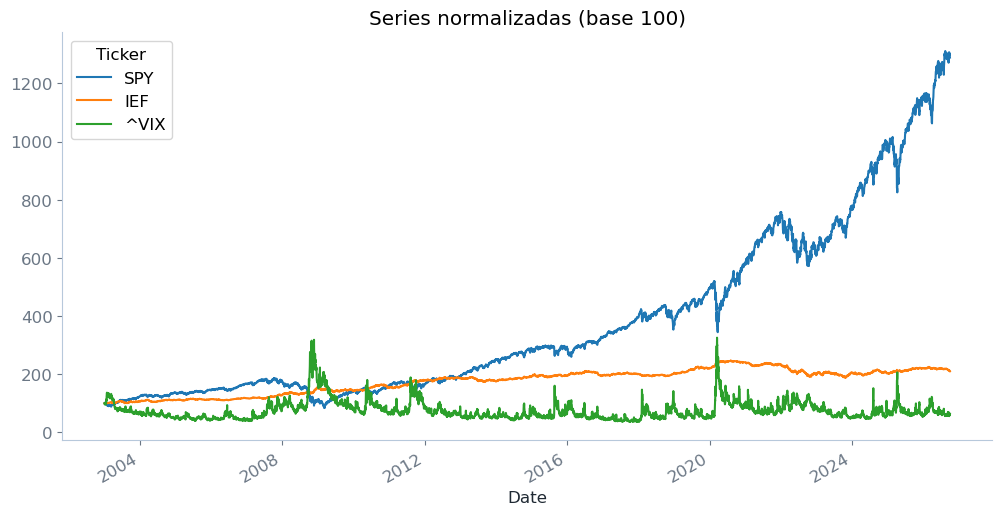

In [60]:
base100 = close / close.iloc[0] * 100
base100.plot(figsize=(12, 6), title="Series normalizadas (base 100)")
plt.show()

IEF es la serie más estable. SPY muestra crecimiento de largo plazo, con caídas fuertes. El VIX tiene picos en momentos de estrés, y esas subidas coinciden con las bajas de SPY: no parece casualidad.

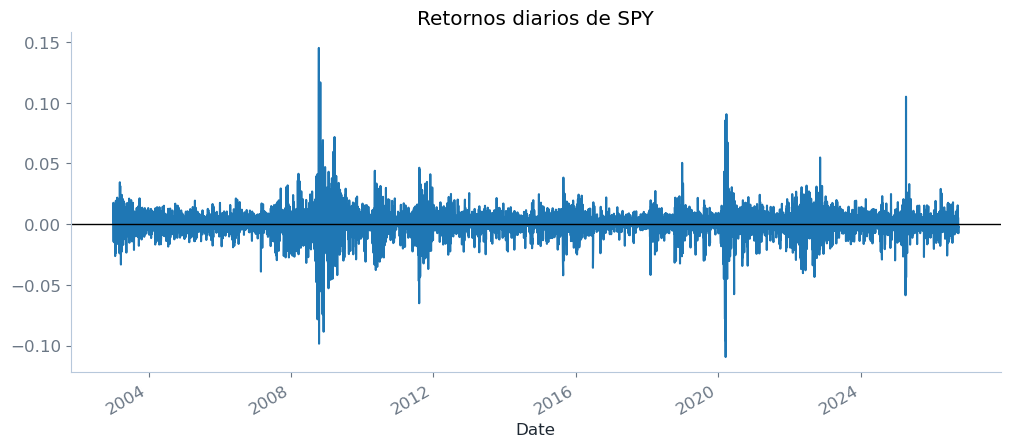

In [61]:
close["SPY_ret"] = close["SPY"].pct_change()

close["SPY_ret"].plot(figsize=(12, 5), title="Retornos diarios de SPY")
plt.axhline(0, color="black", linewidth=1)
plt.show()

Retorno > 0: SPY subió ese día. Retorno < 0: SPY bajó ese día.

Lo importante es qué tan lejos está del 0. Cerca de 0 indica días relativamente tranquilos; donde vemos picos enormes, los retornos diarios fueron mucho más extremos. Acá se ve lo que queremos modelar: **la volatilidad no es constante en el tiempo**. Hay épocas más movidas y épocas más tranquilas, y tienden a agruparse.

In [62]:
close["SPY_log_ret"] = np.log(close["SPY"] / close["SPY"].shift(1))

La ventaja del retorno logarítmico es matemática: se suma bien a lo largo del tiempo, y es el que se usa habitualmente para modelar retornos y volatilidad.

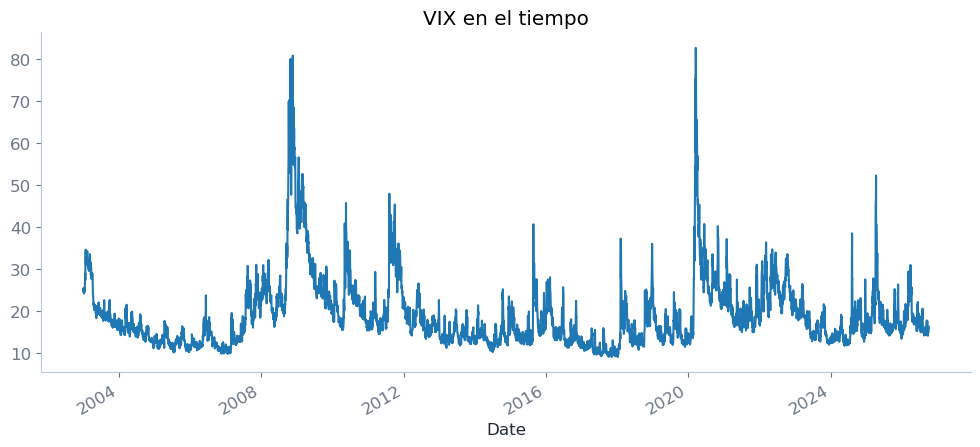

In [63]:
close["^VIX"].plot(figsize=(12, 5), title="VIX en el tiempo")
plt.show()

El VIX presenta picos pronunciados en períodos de estrés financiero, que coinciden visualmente con las etapas de mayor variabilidad en los retornos del S&P 500. Más incertidumbre o volatilidad esperada implica un VIX más alto.

## 5. Volatilidad realizada y tabla mensual

In [64]:
rv_mensual = close["SPY_log_ret"].resample("ME").std() * np.sqrt(252)
rv_mensual.name = "RV_1m"

dias_por_mes = close["SPY_log_ret"].resample("ME").count()
print("Mínimo de días hábiles en un mes:", dias_por_mes.min())

rv_mensual.head()

Mínimo de días hábiles en un mes: 19


Date
2003-01-31    0.210732
2003-02-28    0.184485
2003-03-31    0.269243
2003-04-30    0.186841
2003-05-31    0.155598
Freq: ME, Name: RV_1m, dtype: float64

Tomamos todos los retornos logarítmicos diarios de SPY (cada valor dice cuánto cambió SPY de un día al siguiente). `resample("ME")` los agrupa por mes y `std()` calcula el desvío estándar: la volatilidad mide qué tan dispersos están los retornos.

Para anualizar: si los retornos diarios fueran independientes y con la misma varianza, $\mathrm{Var}(r_{anual}) = 252 \cdot \sigma^2_{diario}$, porque hay aproximadamente 252 días hábiles en un año. Entonces $\sigma_{anual} = \sigma_{diario}\sqrt{252}$.

El control de días por mes confirma que ningún mes quedó con muy pocas observaciones.

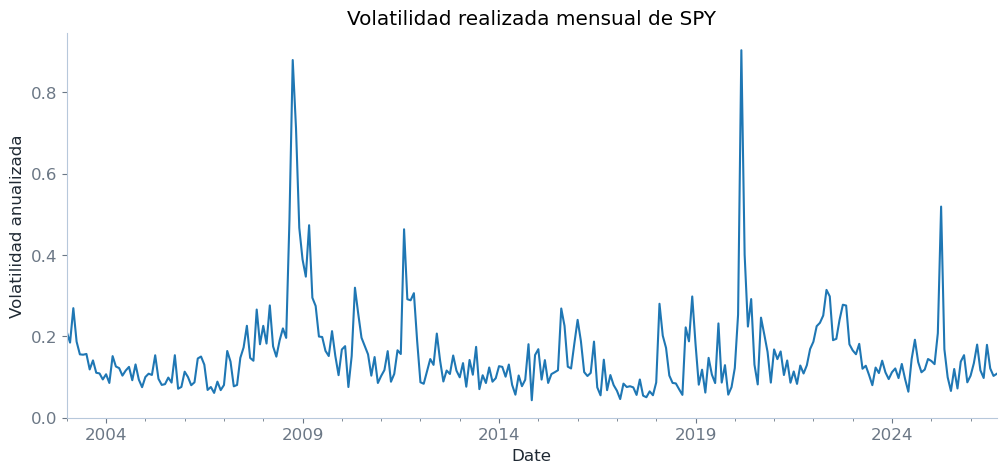

In [65]:
rv_mensual.plot(figsize=(12, 5), title="Volatilidad realizada mensual de SPY")
plt.ylabel("Volatilidad anualizada")
plt.show()

In [66]:
mensual = rv_mensual.to_frame()

mensual["RV_3m"] = mensual["RV_1m"].rolling(3).mean()
mensual["RV_12m"] = mensual["RV_1m"].rolling(12).mean()

mensual.head(15)

,RV_1m,RV_3m,RV_12m
Date,,,
2003-01-31,0.210732,NaN,NaN
2003-02-28,0.184485,NaN,NaN
2003-03-31,0.269243,0.221487,NaN
2003-04-30,0.186841,0.213523,NaN
2003-05-31,0.155598,0.203894,NaN
2003-06-30,0.154728,0.165723,NaN
2003-07-31,0.156607,0.155645,NaN
2003-08-31,0.118468,0.143268,NaN
2003-09-30,0.140749,0.138608,NaN


Agrupamos la volatilidad de los últimos 3 y de los últimos 12 meses. Así tenemos tres variables: volatilidad del último mes, de los últimos 3 meses y de los últimos 12 meses.

Los nulos del principio tienen sentido: en los primeros meses todavía no hay suficiente historia para calcular esos promedios.

In [67]:
vix_mensual = close["^VIX"].resample("ME").last()
vix_mensual.name = "VIX"
mensual = mensual.join(vix_mensual)

**Corrección.** En la versión anterior `SPY_ret_1m` se calculaba pero nunca se agregaba a la tabla `mensual` (la columna aparecía solo porque la celda se había corrido en otra versión). Al correr el notebook de arriba a abajo fallaba más adelante. Ahora se agrega explícitamente con `join`.

In [68]:
spy_mensual = close["SPY"].resample("ME").last()
ief_mensual = close["IEF"].resample("ME").last()

ret_spy_mensual = spy_mensual.pct_change()
ret_spy_mensual.name = "SPY_ret_1m"
mensual = mensual.join(ret_spy_mensual)

max_spy = spy_mensual.cummax()
drawdown_spy = spy_mensual / max_spy - 1
drawdown_spy.name = "Drawdown"
mensual = mensual.join(drawdown_spy)

mensual.head(15)

,RV_1m,RV_3m,RV_12m,VIX,SPY_ret_1m,Drawdown
Date,,,,,,
2003-01-31,0.210732,NaN,NaN,31.170000,NaN,0.000000
2003-02-28,0.184485,NaN,NaN,29.629999,-0.013479,-0.013479
2003-03-31,0.269243,0.221487,NaN,29.150000,0.002140,-0.011368
2003-04-30,0.186841,0.213523,NaN,21.209999,0.084612,0.000000
2003-05-31,0.155598,0.203894,NaN,19.469999,0.054836,0.000000
2003-06-30,0.154728,0.165723,NaN,19.520000,0.010652,0.000000
2003-07-31,0.156607,0.155645,NaN,19.490000,0.018027,0.000000
2003-08-31,0.118468,0.143268,NaN,18.629999,0.020626,0.000000
2003-09-30,0.140749,0.138608,NaN,22.719999,-0.010906,-0.010906


## 6. Target y regla de información

Todas las features se conocen al cierre del mes $t$. El target es la volatilidad realizada del mes $t+1$, que se obtiene desplazando la serie un mes hacia atrás con `shift(-1)`.

In [69]:
mensual["RV_next"] = mensual["RV_1m"].shift(-1)

features_base = ["RV_1m", "RV_3m", "RV_12m", "VIX", "SPY_ret_1m", "Drawdown"]
data_modelo = mensual[features_base + ["RV_next"]].dropna().copy()

data_modelo["log_RV_1m"] = np.log(data_modelo["RV_1m"])
data_modelo["log_RV_3m"] = np.log(data_modelo["RV_3m"])
data_modelo["log_RV_12m"] = np.log(data_modelo["RV_12m"])
data_modelo["log_VIX"] = np.log(data_modelo["VIX"])
data_modelo["target_log"] = np.log(data_modelo["RV_next"])

print("Observaciones mensuales para modelar:", len(data_modelo))
print("Desde", data_modelo.index.min().date(), "hasta", data_modelo.index.max().date())
data_modelo.head()

Observaciones mensuales para modelar: 273
Desde 2003-12-31 hasta 2026-08-31


,RV_1m,RV_3m,RV_12m,VIX,SPY_ret_1m,Drawdown,RV_next,log_RV_1m,log_RV_3m,log_RV_12m,log_VIX,target_log
Date,,,,,,,,,,,,
2003-12-31,0.093914,0.104298,0.157529,18.309999,0.050314,0.000000,0.106619,-2.365373,-2.260502,-1.848147,2.907447,-2.238492
2004-01-31,0.106619,0.103066,0.148853,16.629999,0.019770,0.000000,0.085238,-2.238492,-2.272384,-1.904798,2.811208,-2.462310
2004-02-29,0.085238,0.095257,0.140582,14.550000,0.013571,0.000000,0.151295,-2.462310,-2.351176,-1.961963,2.677591,-1.888521
2004-03-31,0.151295,0.114384,0.130753,16.740000,-0.013246,-0.013246,0.125703,-1.888521,-2.168193,-2.034444,2.817801,-2.073832
2004-04-30,0.125703,0.120745,0.125658,17.190001,-0.018921,-0.031916,0.121724,-2.073832,-2.114071,-2.074188,2.844328,-2.106001


In [70]:
# Verificación de que no hay información futura: el target de t debe ser la RV de t+1
chequeo = (data_modelo["RV_next"].iloc[:-1].values == data_modelo["RV_1m"].iloc[1:].values).all()
print("RV_next(t) == RV_1m(t+1) en toda la muestra:", chequeo)

RV_next(t) == RV_1m(t+1) en toda la muestra: True


## 7. Análisis exploratorio

Se completan gráficos: histogramas de la volatilidad y su logaritmo, comparación VIX vs. RV, y marcado de períodos de alta volatilidad.

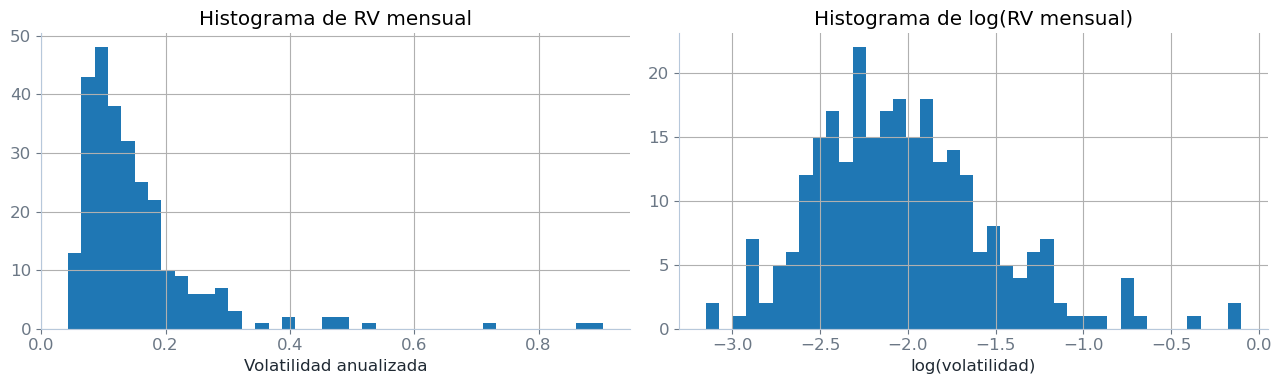

Asimetría RV: 3.62 | Asimetría log(RV): 0.76


In [71]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

data_modelo["RV_1m"].hist(bins=40, ax=axes[0])
axes[0].set_title("Histograma de RV mensual")
axes[0].set_xlabel("Volatilidad anualizada")

data_modelo["log_RV_1m"].hist(bins=40, ax=axes[1])
axes[1].set_title("Histograma de log(RV mensual)")
axes[1].set_xlabel("log(volatilidad)")

plt.tight_layout()
plt.show()

print("Asimetría RV:", round(data_modelo["RV_1m"].skew(), 2),
      "| Asimetría log(RV):", round(data_modelo["log_RV_1m"].skew(), 2))

La RV tiene una cola derecha larga: muchos meses tranquilos y pocos meses muy volátiles. El logaritmo reduce esa asimetría, y por eso se usa $\log(RV_{t+1})$ como target.

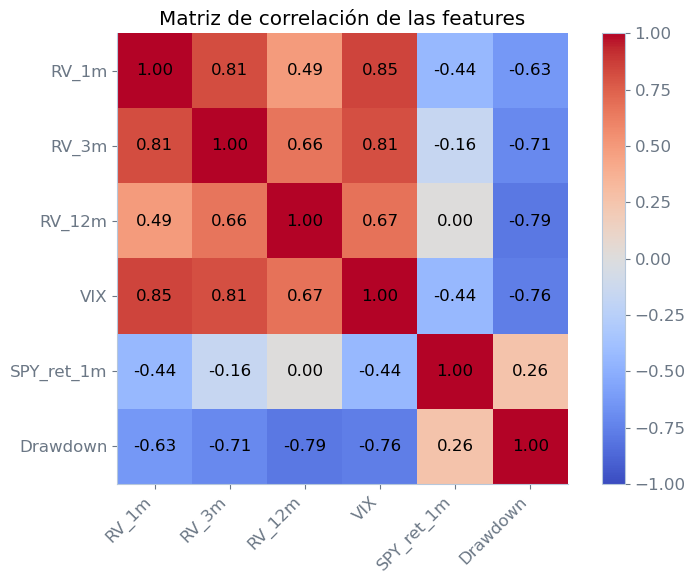

In [72]:
eda = data_modelo[features_base]
corr = eda.corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black")
plt.title("Matriz de correlación de las features")
plt.tight_layout()
plt.show()

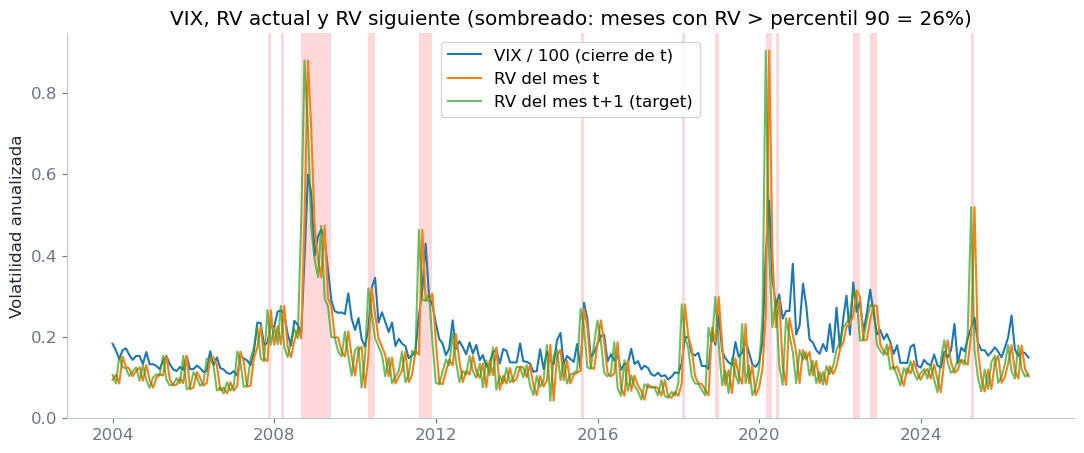

In [73]:
umbral_alta_vol = data_modelo["RV_1m"].quantile(0.90)
alta_vol = data_modelo["RV_1m"] > umbral_alta_vol

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(data_modelo.index, data_modelo["VIX"] / 100, label="VIX / 100 (cierre de t)")
ax.plot(data_modelo.index, data_modelo["RV_1m"], label="RV del mes t")
ax.plot(data_modelo.index, data_modelo["RV_next"], label="RV del mes t+1 (target)", alpha=0.7)

for fecha in data_modelo.index[alta_vol]:
    ax.axvspan(fecha - pd.offsets.MonthBegin(1), fecha, color="red", alpha=0.15, linewidth=0)

ax.set_title(f"VIX, RV actual y RV siguiente (sombreado: meses con RV > percentil 90 = {umbral_alta_vol:.0%})")
ax.set_ylabel("Volatilidad anualizada")
ax.legend()
plt.show()

El VIX se mueve junto con la volatilidad realizada y suele estar por encima de ella (el mercado de opciones cobra una prima por asegurarse). Los meses de alta volatilidad aparecen agrupados (2008, 2011, 2020, 2022), lo que respalda la hipótesis de persistencia.

## 8. Modelos y validación walk-forward

Se comparan cuatro predictores de la volatilidad del mes siguiente:

| Modelo | Features | Papel |
|---|---|---|
| Naive | RV del mes t | Benchmark mínimo |
| HAR | log RV 1m, 3m, 12m | Benchmark lineal clásico |
| HAR + VIX | log RV 1m, 3m, 12m y log VIX | Benchmark lineal con la misma información clave que el RF |
| Random Forest | las seis features | Modelo principal de ML |

La validación es walk-forward con ventana expansiva: en cada mes se entrena con todo el pasado disponible y se predice el mes siguiente, que el modelo nunca vio. Nunca se mezclan pasado y futuro.

In [74]:
def walk_forward(X, y, crear_modelo, inicio):
    # Entrena con las filas [0, i) y predice la fila i, para cada i desde 'inicio'.
    # Devuelve la predicción en escala de volatilidad (aplica exp al log predicho).
    predicciones_log = []
    for i in range(inicio, len(X)):
        modelo = crear_modelo()
        modelo.fit(X.iloc[:i], y.iloc[:i])
        predicciones_log.append(modelo.predict(X.iloc[[i]])[0])
    return pd.Series(np.exp(predicciones_log), index=X.index[inicio:])


features_har = ["log_RV_1m", "log_RV_3m", "log_RV_12m"]
features_har_vix = features_har + ["log_VIX"]
features_rf = features_base

y_log = data_modelo["target_log"]
fechas_test = data_modelo.index[TRAIN_SIZE_INICIAL:]
real_test = data_modelo.loc[fechas_test, "RV_next"]

print("Período de test:", fechas_test.min().date(), "a", fechas_test.max().date(),
      f"({len(fechas_test)} meses)")

Período de test: 2013-12-31 a 2026-08-31 (153 meses)


In [75]:
pred_naive = data_modelo.loc[fechas_test, "RV_1m"]

pred_har = walk_forward(data_modelo[features_har], y_log, LinearRegression, TRAIN_SIZE_INICIAL)
pred_har_vix = walk_forward(data_modelo[features_har_vix], y_log, LinearRegression, TRAIN_SIZE_INICIAL)
pred_rf = walk_forward(data_modelo[features_rf], y_log,
                       lambda: RandomForestRegressor(**RF_PARAMS), TRAIN_SIZE_INICIAL)

predicciones = pd.DataFrame({
    "Naive": pred_naive,
    "HAR": pred_har,
    "HAR_VIX": pred_har_vix,
    "Random_Forest": pred_rf,
})
predicciones.head()

,Naive,HAR,HAR_VIX,Random_Forest
Date,,,,
2013-12-31,0.096993,0.104914,0.103418,0.096879
2014-01-31,0.126546,0.120682,0.145201,0.133121
2014-02-28,0.124800,0.122782,0.110381,0.096263
2014-03-31,0.100632,0.110403,0.104531,0.100681
2014-04-30,0.130563,0.126179,0.106732,0.101818


## 9. Evaluación predictiva fuera de muestra

Todas las métricas se calculan **solo** sobre el período de test, con las mismas fechas para todos los modelos.

In [76]:
def metricas_prediccion(real, preds):
    filas = []
    for nombre in preds.columns:
        filas.append({
            "Modelo": nombre,
            "MAE": mean_absolute_error(real, preds[nombre]),
            "RMSE": np.sqrt(mean_squared_error(real, preds[nombre])),
            "R2": r2_score(real, preds[nombre]),
        })
    return pd.DataFrame(filas).set_index("Modelo")

metricas = metricas_prediccion(real_test, predicciones)
metricas

,MAE,RMSE,R2
Modelo,,,
Naive,0.057634,0.098019,-0.080509
HAR,0.048711,0.085791,0.172256
HAR_VIX,0.044186,0.073075,0.399448
Random_Forest,0.045115,0.078859,0.300630


In [77]:
errores_abs = predicciones.sub(real_test, axis=0).abs()

mejor_modelo = errores_abs.idxmin(axis=1)
print("Cantidad de meses en que cada modelo tuvo el menor error absoluto:")
mejor_modelo.value_counts()

Cantidad de meses en que cada modelo tuvo el menor error absoluto:


HAR_VIX          54
Random_Forest    37
Naive            34
HAR              28
Name: count, dtype: int64

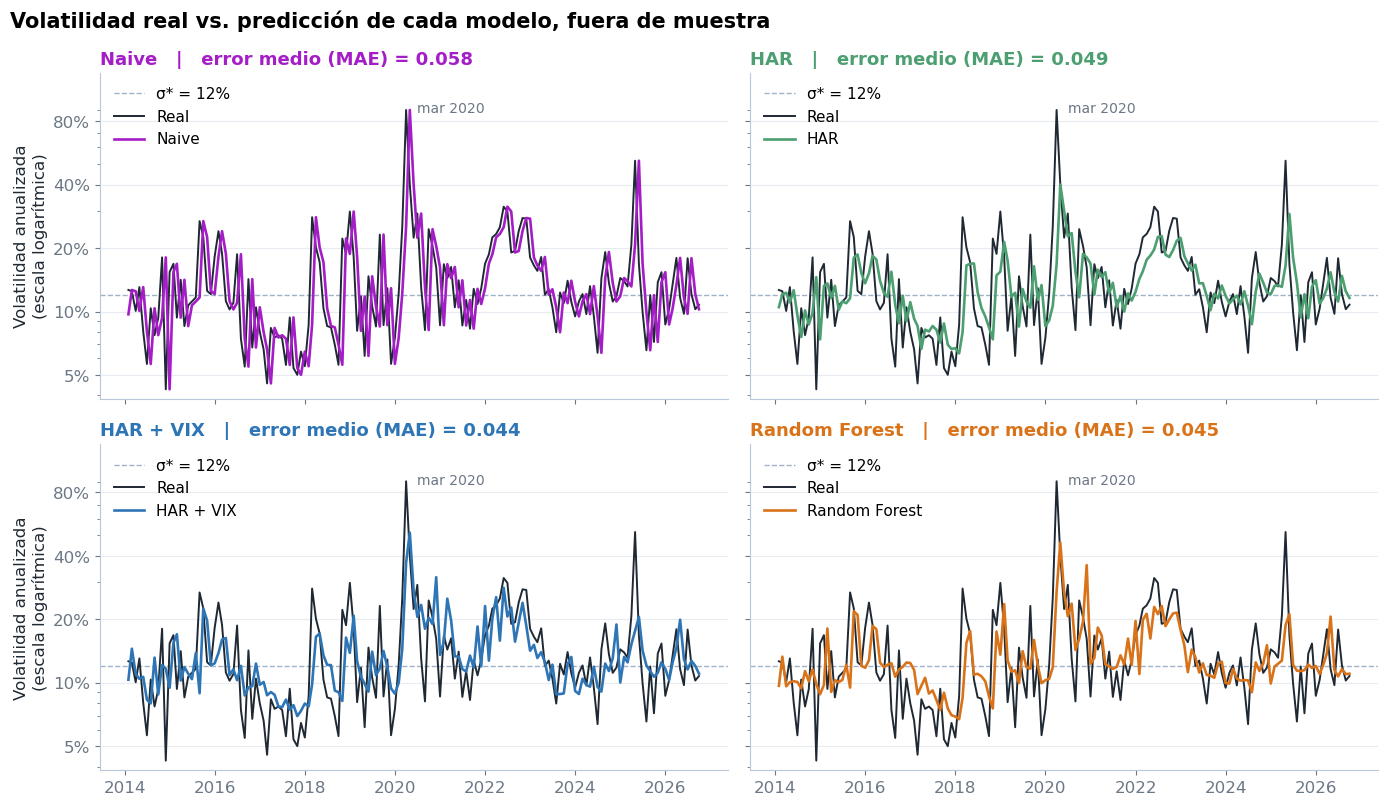

In [104]:
# Volatilidad real vs. predicción: un panel por modelo (línea negra = real, línea de color = predicción).
# El eje vertical es logarítmico: así se ven a la vez los meses calmos y los picos (2020, 2025).
fechas_graf = mes_de_retorno(real_test.index)          # mes que se predice
i_pico = int(np.argmax(real_test.values))
lo = min(real_test.min(), predicciones.min().min()) * 0.9
hi = max(real_test.max(), predicciones.max().max()) * 1.5

with plt.rc_context(ESTILO):
    fig, axs = plt.subplots(2, 2, figsize=(14, 8.2), sharex=True, sharey=True)
    for ax, modelo in zip(axs.ravel(), predicciones.columns):
        color, pred = COLOR_MODELO[modelo], predicciones[modelo]
        mae = (pred - real_test).abs().mean()
        ax.axhline(VOL_OBJETIVO, color=LINEA_SIGMA, lw=1, ls="--", label=f"σ* = {VOL_OBJETIVO:.0%}")
        ax.plot(fechas_graf, real_test.values, color=TINTA, lw=1.4, label="Real")
        ax.plot(fechas_graf, pred.values, color=color, lw=1.9, label=NOMBRE_MODELO[modelo])
        ax.set_yscale("log"); ax.set_ylim(lo, hi)
        ax.yaxis.set_major_locator(FixedLocator(ticks_log(lo, hi))); ax.yaxis.set_major_formatter(pct0)
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
        ax.set_title(f"{NOMBRE_MODELO[modelo]}   |   error medio (MAE) = {mae:.3f}", loc="left", color=color, fontsize=13)
        ax.annotate(etiqueta_mes(fechas_graf[i_pico]), (fechas_graf[i_pico], real_test.values[i_pico]),
                    xytext=(8, -2), textcoords="offset points", fontsize=10, color=SUAVE)
        ax.grid(axis="y", color=GRILLA, lw=.8); ax.set_axisbelow(True)
        ax.legend(loc="upper left", frameon=False, fontsize=11, ncol=1)
    for ax in axs[:, 0]:
        ax.set_ylabel("Volatilidad anualizada\n(escala logarítmica)")
    fig.suptitle("Volatilidad real vs. predicción de cada modelo, fuera de muestra",
                 fontsize=15, fontweight="bold", x=0.01, ha="left")
    plt.tight_layout()
    plt.show()

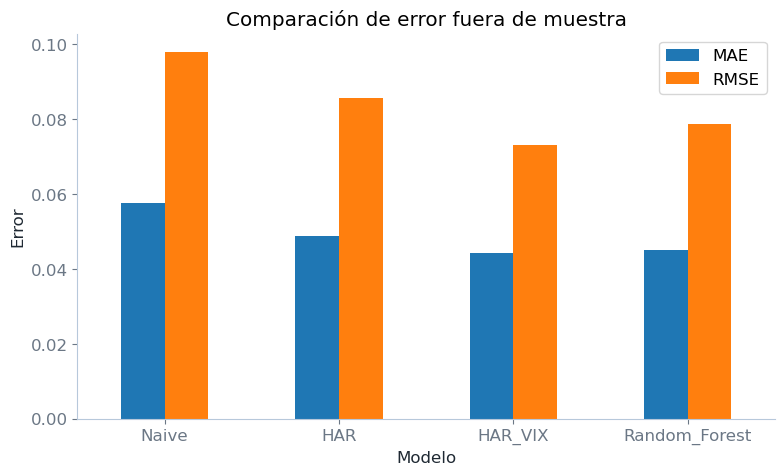

In [79]:
metricas[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5))
plt.title("Comparación de error fuera de muestra")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

**Estabilidad de la mejora.** El RMSE puede estar dominado por pocos meses extremos (por ejemplo, marzo de 2020). Para saber si la ventaja de un modelo es consistente o depende de un episodio, se mira el MAE año por año y las métricas excluyendo 2020.

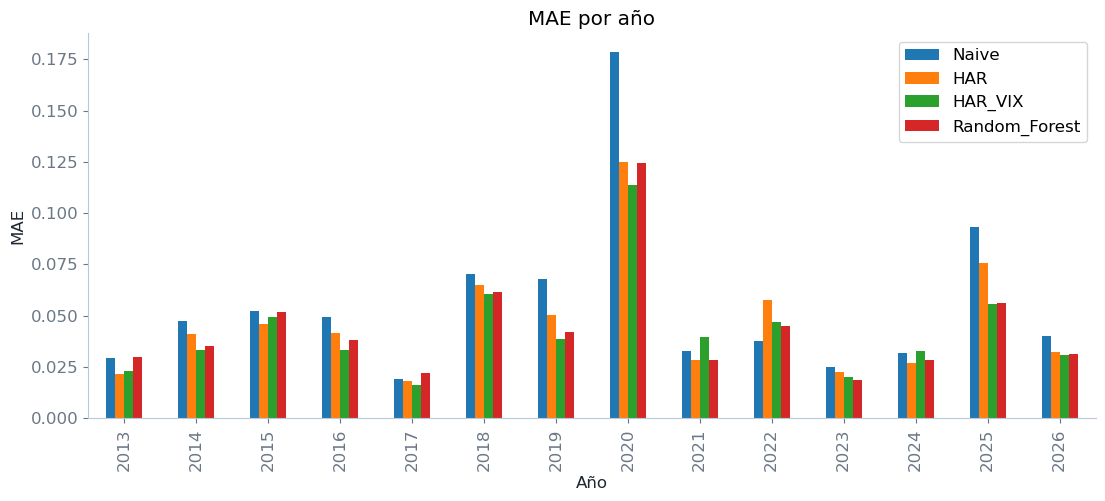

Cantidad de años en que cada modelo tuvo el menor MAE:
HAR_VIX          8
HAR              4
Naive            1
Random_Forest    1
Name: count, dtype: int64


In [80]:
mae_por_anio = errores_abs.groupby(errores_abs.index.year).mean()

mae_por_anio.plot(kind="bar", figsize=(13, 5))
plt.title("MAE por año")
plt.ylabel("MAE")
plt.xlabel("Año")
plt.show()

anio_ganador = mae_por_anio.idxmin(axis=1)
print("Cantidad de años en que cada modelo tuvo el menor MAE:")
print(anio_ganador.value_counts())

In [81]:
sin_2020 = real_test.index.year != 2020
print("Métricas excluyendo 2020:")
metricas_prediccion(real_test[sin_2020], predicciones[sin_2020])

Métricas excluyendo 2020:


,MAE,RMSE,R2
Modelo,,,
Naive,0.047326,0.068902,-0.046434
HAR,0.042240,0.060101,0.203830
HAR_VIX,0.038259,0.056489,0.296639
Random_Forest,0.038358,0.056763,0.289807


### Importancia de variables e interpretación

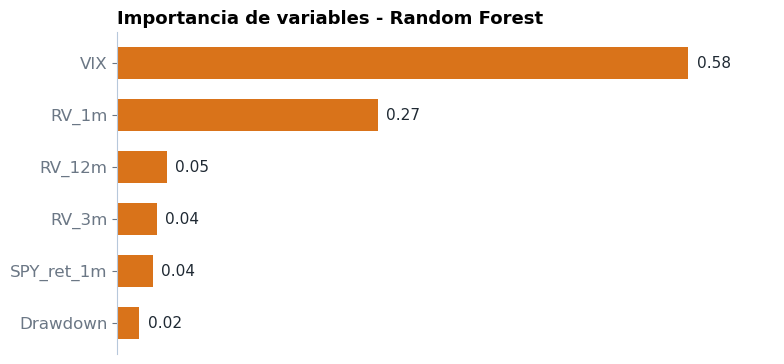

VIX           0.583779
RV_1m         0.266217
RV_12m        0.050588
RV_3m         0.040482
SPY_ret_1m    0.036452
Drawdown      0.022482
dtype: float64

In [105]:
# Nota: este modelo se ajusta con TODA la muestra. Se usa solo para describir
# qué variables usa el bosque, no para evaluar desempeño.
modelo_rf_final = RandomForestRegressor(**RF_PARAMS)
modelo_rf_final.fit(data_modelo[features_rf], y_log)

importancias = pd.Series(modelo_rf_final.feature_importances_,
                         index=features_rf).sort_values(ascending=False)

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(importancias.index, importancias.values, color=COLOR_MODELO["Random_Forest"], height=.62)
    ax.invert_yaxis()
    for y, v in enumerate(importancias.values):
        ax.text(v + importancias.max() * 0.015, y, f"{v:.2f}", va="center", fontsize=11, color=TINTA)
    ax.set_xlim(0, importancias.max() * 1.15)
    ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    ax.set_title("Importancia de variables - Random Forest", loc="left", fontsize=13)
    plt.tight_layout()
    plt.show()
importancias

In [83]:
modelo_har_vix_final = LinearRegression().fit(data_modelo[features_har_vix], y_log)
pd.Series(modelo_har_vix_final.coef_, index=features_har_vix, name="Coeficiente HAR+VIX")

log_RV_1m     0.034660
log_RV_3m     0.032936
log_RV_12m   -0.249084
log_VIX       1.163285
Name: Coeficiente HAR+VIX, dtype: float64

La matriz de correlación mostró alta correlación entre el VIX y las medidas de volatilidad histórica. En el Random Forest, el VIX resulta la variable de mayor importancia, seguida por la volatilidad del último mes. Las variables de horizontes más largos y el drawdown aportan menos, posiblemente porque parte de su información ya está contenida en las variables más recientes.

Los coeficientes del HAR + VIX permiten ver lo mismo en un modelo lineal interpretable. La importancia del RF se calcula sobre toda la muestra, así que es descriptiva y no una medida de desempeño fuera de muestra.

## 10. Regla del portfolio y backtest

Con la predicción $\hat\sigma_{t+1}$ hecha al cierre de $t$:

$$w_{SPY,t} = \min\left(1, \frac{\sigma^*}{\hat\sigma_{t+1}}\right), \qquad w_{IEF,t} = 1 - w_{SPY,t}$$

Los pesos decididos en $t$ se aplican a los retornos de $t+1$. Para dos activos, el turnover $\frac{1}{2}\sum_i |w_{i,t} - w_{i,t-1}|$ es igual a $|w_{SPY,t} - w_{SPY,t-1}|$. El costo es $0{,}10\% \times$ turnover y se descuenta del retorno del mes.


In [84]:
spy_ret_next = spy_mensual.pct_change().shift(-1)
ief_ret_next = ief_mensual.pct_change().shift(-1)

spy_test = spy_ret_next.loc[fechas_test]
ief_test = ief_ret_next.loc[fechas_test]

# Tasa libre de riesgo: DTB3 al cierre de t (conocida en t), aplicada al mes t+1
dtb3_mensual = dtb3.set_index("Date")["RF_3M"].resample("ME").last()
rf_test = (dtb3_mensual / 100 / 12).reindex(fechas_test)
print("Meses sin tasa libre de riesgo:", rf_test.isna().sum())

Meses sin tasa libre de riesgo: 0


In [85]:
def pesos_vol_target(pred, vol_objetivo):
    return (vol_objetivo / pred).clip(upper=1)


def backtest(peso_spy, costo):
    # Retorno neto, peso en SPY y turnover de una estrategia SPY/IEF
    peso_spy = peso_spy.reindex(fechas_test)
    ret_bruto = peso_spy * spy_test + (1 - peso_spy) * ief_test
    turnover = peso_spy.diff().abs().fillna(0)
    ret_neto = ret_bruto - costo * turnover
    return ret_neto, peso_spy, turnover


def armar_estrategias(vol_objetivo, costo):
    estrategias = {
        "SPY": pd.Series(1.0, index=fechas_test),
        "60_40": pd.Series(0.6, index=fechas_test),
    }
    for nombre in ["Naive", "HAR", "HAR_VIX", "Random_Forest"]:
        estrategias[f"VolTarget_{nombre}"] = pesos_vol_target(predicciones[nombre], vol_objetivo)

    retornos, pesos, turnovers = {}, {}, {}
    for nombre, peso in estrategias.items():
        retornos[nombre], pesos[nombre], turnovers[nombre] = backtest(peso, costo)
    return pd.DataFrame(retornos), pd.DataFrame(pesos), pd.DataFrame(turnovers)


def metricas_financieras(retornos, pesos, turnovers, rf):
    n_meses = len(retornos)
    crecimiento = (1 + retornos).cumprod()
    drawdown = crecimiento / crecimiento.cummax() - 1
    exceso = retornos.sub(rf, axis=0)
    return pd.DataFrame({
        "Retorno_anual": (1 + retornos).prod() ** (12 / n_meses) - 1,
        "Volatilidad_anual": retornos.std() * np.sqrt(12),
        "Sharpe": exceso.mean() / exceso.std() * np.sqrt(12),
        "Max_Drawdown": drawdown.min(),
        "Turnover_medio": turnovers.mean(),
        "Peso_SPY_medio": pesos.mean(),
        "Meses_100%_SPY": (pesos >= 0.9999).mean(),
    })

In [86]:
# Caso base, sin costos (bruto) y con costos (neto)
ret_bruto, pesos_base, turn_base = armar_estrategias(VOL_OBJETIVO, costo=0.0)
ret_neto, _, _ = armar_estrategias(VOL_OBJETIVO, costo=COSTO_TRANSACCION)

# Todas las estrategias sobre exactamente el mismo período
ret_bruto = ret_bruto.dropna()
ret_neto = ret_neto.loc[ret_bruto.index]
rf_bt = rf_test.loc[ret_bruto.index]

resultados_brutos = metricas_financieras(ret_bruto, pesos_base.loc[ret_bruto.index],
                                         turn_base.loc[ret_bruto.index], rf_bt)
resultados_netos = metricas_financieras(ret_neto, pesos_base.loc[ret_bruto.index],
                                        turn_base.loc[ret_bruto.index], rf_bt)

print(f"Backtest: {ret_bruto.index.min().date()} a {ret_bruto.index.max().date()} "
      f"({len(ret_bruto)} meses), σ* = {VOL_OBJETIVO:.0%}, costo = {COSTO_TRANSACCION:.2%}")
resultados_netos.style.format({
    "Retorno_anual": "{:.2%}", "Volatilidad_anual": "{:.2%}", "Sharpe": "{:.3f}",
    "Max_Drawdown": "{:.2%}", "Turnover_medio": "{:.3f}", "Peso_SPY_medio": "{:.2%}",
    "Meses_100%_SPY": "{:.0%}"})

Backtest: 2013-12-31 a 2026-08-31 (153 meses), σ* = 12%, costo = 0.10%


,Retorno_anual,Volatilidad_anual,Sharpe,Max_Drawdown,Turnover_medio,Peso_SPY_medio,Meses_100%_SPY
SPY,13.65%,14.49%,0.828,-23.93%,0.000,100.00%,100%
60_40,8.90%,9.32%,0.760,-20.51%,0.000,60.00%,0%
VolTarget_Naive,10.55%,10.98%,0.799,-20.66%,0.130,84.30%,48%
VolTarget_HAR,10.61%,11.74%,0.760,-21.42%,0.080,87.85%,43%
VolTarget_HAR_VIX,10.36%,11.08%,0.779,-23.22%,0.102,87.53%,47%
VolTarget_Random_Forest,10.24%,11.40%,0.750,-22.59%,0.095,89.07%,53%


In [87]:
comparacion_costos = pd.DataFrame({
    "Retorno_bruto": resultados_brutos["Retorno_anual"],
    "Retorno_neto": resultados_netos["Retorno_anual"],
    "Sharpe_bruto": resultados_brutos["Sharpe"],
    "Sharpe_neto": resultados_netos["Sharpe"],
})
comparacion_costos["Diferencia_retorno"] = comparacion_costos["Retorno_neto"] - comparacion_costos["Retorno_bruto"]
comparacion_costos

,Retorno_bruto,Retorno_neto,Sharpe_bruto,Sharpe_neto,Diferencia_retorno
SPY,0.136470,0.136470,0.828425,0.828425,0.000000
60_40,0.089022,0.089022,0.760351,0.760351,0.000000
VolTarget_Naive,0.107153,0.105450,0.813240,0.799348,-0.001703
VolTarget_HAR,0.107180,0.106133,0.768389,0.760327,-0.001047
VolTarget_HAR_VIX,0.104915,0.103565,0.790350,0.778971,-0.001350
VolTarget_Random_Forest,0.103602,0.102359,0.760212,0.750370,-0.001243


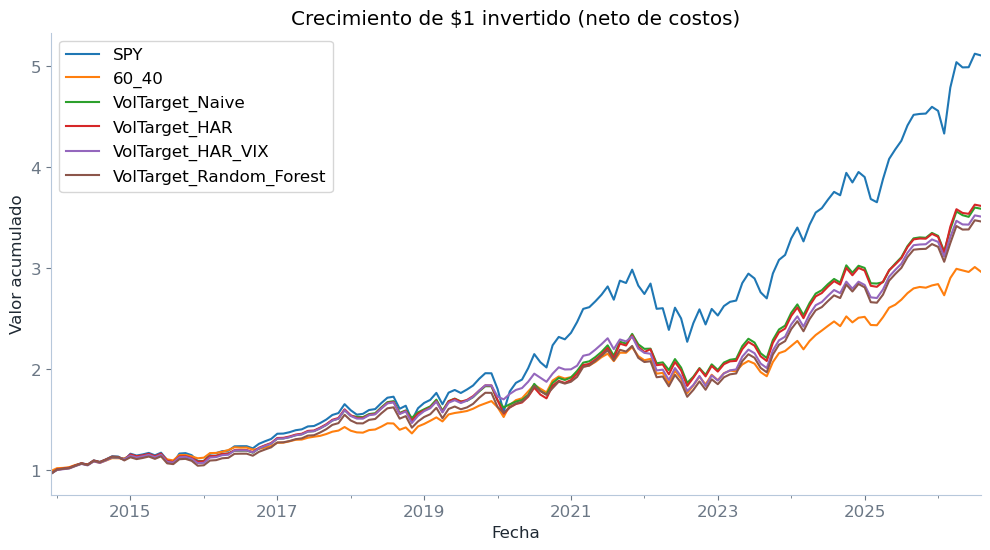

In [88]:
crecimiento_neto = (1 + ret_neto).cumprod()

crecimiento_neto.plot(figsize=(12, 6), title="Crecimiento de $1 invertido (neto de costos)")
plt.ylabel("Valor acumulado")
plt.xlabel("Fecha")
plt.show()

**Gráfico de drawdowns.**

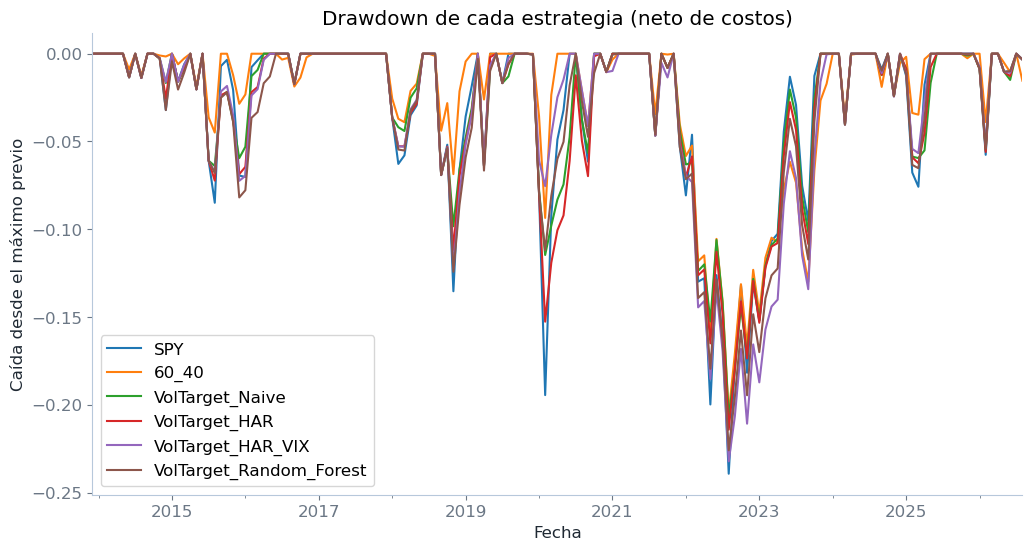

In [89]:
drawdowns_netos = crecimiento_neto / crecimiento_neto.cummax() - 1

drawdowns_netos.plot(figsize=(12, 6), title="Drawdown de cada estrategia (neto de costos)")
plt.ylabel("Caída desde el máximo previo")
plt.xlabel("Fecha")
plt.show()

### ¿Por qué una mejor predicción no se traduce necesariamente en mejor Sharpe?

La regla tiene un tope: el peso en SPY nunca supera 100%. Si la volatilidad prevista está por debajo de $\sigma^*$, el peso queda en 100% sin importar cuán buena sea la predicción. La calidad del modelo solo cambia la cartera en los meses en que la volatilidad prevista supera el objetivo. La columna `Meses_100%_SPY` de la tabla anterior y el gráfico siguiente muestran cuánto pesa este efecto.

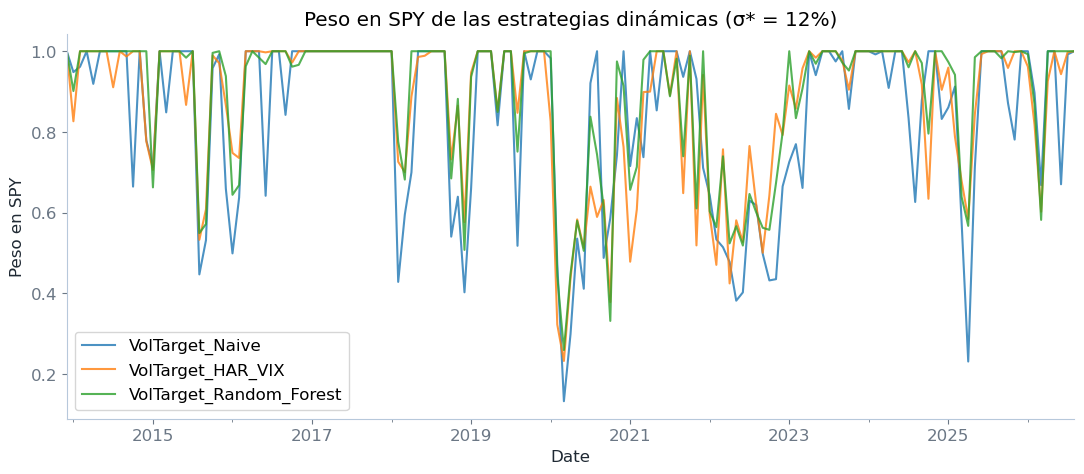

In [90]:
pesos_base.loc[ret_bruto.index, ["VolTarget_Naive", "VolTarget_HAR_VIX", "VolTarget_Random_Forest"]].plot(
    figsize=(13, 5), alpha=0.8, title=f"Peso en SPY de las estrategias dinámicas (σ* = {VOL_OBJETIVO:.0%})")
plt.ylabel("Peso en SPY")
plt.show()

In [91]:
# Errores de predicción separados según si el mes terminó por encima o por debajo de σ*
mes_activo = real_test > VOL_OBJETIVO
print(f"Meses con RV real > σ*: {mes_activo.mean():.0%} del test\n")
pd.DataFrame({
    "MAE con RV > σ*": errores_abs[mes_activo].mean(),
    "MAE con RV <= σ*": errores_abs[~mes_activo].mean(),
})

Meses con RV real > σ*: 52% del test



,MAE con RV > σ*,MAE con RV <= σ*
Naive,0.078006,0.035884
HAR,0.063314,0.033121
HAR_VIX,0.058907,0.028470
Random_Forest,0.060908,0.028255


Otro factor: la estrategia naive reacciona más rápido después de un mes turbulento, porque copia directamente la volatilidad del mes anterior. Los modelos suavizan más. Esa reacción rápida puede ser útil en el backtest aunque el error promedio sea mayor.

**Retornos por año.** En años en que acciones y bonos cayeron juntos (como 2022), moverse hacia IEF no protege. El rol defensivo de los bonos es empírico, no una garantía.

In [92]:
retornos_anuales = (1 + ret_neto).groupby(ret_neto.index.year).prod() - 1
ief_anual = (1 + ief_test.loc[ret_neto.index]).groupby(ret_neto.index.year).prod() - 1
retornos_anuales["IEF_solo"] = ief_anual

retornos_anuales.style.format("{:.1%}")

,SPY,60_40,VolTarget_Naive,VolTarget_HAR,VolTarget_HAR_VIX,VolTarget_Random_Forest,IEF_solo
Date,,,,,,,
2013,-3.5%,-0.9%,-3.5%,-3.5%,-3.5%,-3.5%,3.1%
2014,14.1%,12.7%,15.0%,14.5%,14.9%,13.7%,10.4%
2015,-0.9%,0.0%,-2.3%,-1.8%,-3.6%,-4.8%,0.6%
2016,20.0%,10.8%,16.6%,17.1%,18.1%,17.5%,-2.0%
2017,26.3%,15.2%,26.3%,26.3%,26.3%,26.3%,0.1%
2018,-2.4%,0.4%,-1.4%,-2.7%,-3.5%,-4.3%,3.9%
2019,21.4%,17.5%,16.4%,17.9%,19.6%,19.1%,11.0%
2020,17.2%,13.3%,3.4%,1.4%,8.6%,5.2%,5.2%
2021,23.2%,11.6%,18.7%,19.2%,10.3%,13.7%,-4.3%


## 11. Robustez: sensibilidad a la volatilidad objetivo y a los costos

Queremos verificar si la conclusión se mantiene al cambiar $\sigma^*$ (10%, 12%, 15%) y los costos de transacción. Se mantienen fijos los modelos y sus predicciones; solo cambia la regla.

In [93]:
filas = []
for vol_obj in VOL_OBJETIVO_SENS:
    for costo in COSTOS_SENS:
        r, p, t = armar_estrategias(vol_obj, costo)
        r = r.loc[ret_bruto.index]
        m = metricas_financieras(r, p.loc[r.index], t.loc[r.index], rf_bt)
        for estrategia in m.index:
            filas.append({"σ*": vol_obj, "Costo": costo, "Estrategia": estrategia,
                          "Sharpe": m.loc[estrategia, "Sharpe"],
                          "Max_Drawdown": m.loc[estrategia, "Max_Drawdown"]})

sensibilidad = pd.DataFrame(filas)

tabla_sharpe = sensibilidad.pivot_table(index="Estrategia", columns=["σ*", "Costo"], values="Sharpe")
tabla_sharpe.style.format("{:.3f}").background_gradient(axis=0, cmap="RdYlGn")

In [94]:
tabla_mdd = sensibilidad.pivot_table(index="Estrategia", columns=["σ*", "Costo"], values="Max_Drawdown")
tabla_mdd.style.format("{:.1%}").background_gradient(axis=0, cmap="RdYlGn")

In [95]:
# ¿Qué estrategia dinámica tiene el mejor Sharpe en cada escenario?
dinamicas = sensibilidad[sensibilidad["Estrategia"].str.startswith("VolTarget")]
mejor_por_escenario = dinamicas.loc[dinamicas.groupby(["σ*", "Costo"])["Sharpe"].idxmax(),
                                    ["σ*", "Costo", "Estrategia", "Sharpe"]]
mejor_por_escenario.reset_index(drop=True)

,σ*,Costo,Estrategia,Sharpe
0,0.10,0.0000,VolTarget_Naive,0.777559
1,0.10,0.0010,VolTarget_Naive,0.757112
2,0.10,0.0025,VolTarget_Naive,0.726375
3,0.12,0.0000,VolTarget_Naive,0.813240
4,0.12,0.0010,VolTarget_Naive,0.799348
5,0.12,0.0025,VolTarget_Naive,0.778458
6,0.15,0.0000,VolTarget_Naive,0.830065
7,0.15,0.0010,VolTarget_Naive,0.821800
8,0.15,0.0025,VolTarget_Naive,0.809373


## 12. Resumen automático de resultados

In [96]:
m = metricas
f = resultados_netos

print("PREDICCIÓN (fuera de muestra)")
print(f"  Mejor MAE: {m['MAE'].idxmin()} ({m['MAE'].min():.4f})")
print(f"  Mejor RMSE: {m['RMSE'].idxmin()} ({m['RMSE'].min():.4f})")
print(f"  RF vs HAR+VIX -> MAE: {m.loc['Random_Forest', 'MAE']:.4f} vs {m.loc['HAR_VIX', 'MAE']:.4f} | "
      f"RMSE: {m.loc['Random_Forest', 'RMSE']:.4f} vs {m.loc['HAR_VIX', 'RMSE']:.4f}")

print("\nDECISIÓN (caso base, neto de costos)")
print("  Ranking por Sharpe:")
for nombre, valor in f["Sharpe"].sort_values(ascending=False).items():
    print(f"    {nombre:<25} {valor:.3f}   MDD {f.loc[nombre, 'Max_Drawdown']:.1%}")

print("\nROBUSTEZ")
print("  Estrategia dinámica con mejor Sharpe por escenario:")
print(mejor_por_escenario["Estrategia"].value_counts().to_string())

PREDICCIÓN (fuera de muestra)
  Mejor MAE: HAR_VIX (0.0442)
  Mejor RMSE: HAR_VIX (0.0731)
  RF vs HAR+VIX -> MAE: 0.0451 vs 0.0442 | RMSE: 0.0789 vs 0.0731

DECISIÓN (caso base, neto de costos)
  Ranking por Sharpe:
    SPY                       0.828   MDD -23.9%
    VolTarget_Naive           0.799   MDD -20.7%
    VolTarget_HAR_VIX         0.779   MDD -23.2%
    60_40                     0.760   MDD -20.5%
    VolTarget_HAR             0.760   MDD -21.4%
    VolTarget_Random_Forest   0.750   MDD -22.6%

ROBUSTEZ
  Estrategia dinámica con mejor Sharpe por escenario:
Estrategia
VolTarget_Naive    9


## Conclusiones

**1. Predicción.** Los tres modelos con variables explicativas predicen mejor la volatilidad del mes siguiente que el Naive (MAE 0,058; R² negativo). El que menos error tiene es el **HAR + VIX** (MAE 0,044; RMSE 0,073; R² 0,40), seguido de cerca por el Random Forest (MAE 0,045; R² 0,30). El HAR sin VIX queda más atrás (MAE 0,049; R² 0,17). La mejora viene de **incorporar el VIX**, no de la no linealidad del Random Forest: un modelo lineal simple con VIX iguala o supera al RF.

**2. Cartera.** Ninguna estrategia de volatility targeting superó a SPY en Sharpe neto (SPY 0,83; Naive 0,80; HAR + VIX 0,78; HAR 0,76; RF 0,75; 60/40 0,76). El volatility targeting sí redujo el riesgo en algunos casos (por ejemplo, drawdown máximo de -20,7% con Naive contra -23,9% de SPY), pero a costa de retorno.

**3. Mejor predicción no implica mejor decisión.** El ranking por error se invierte en la cartera: el Naive es el que peor predice pero tiene el mejor Sharpe entre las estrategias dinámicas, y el RF, segundo en error, tiene el peor. Una posible explicación es que la regla solo reduce el peso en SPY cuando la volatilidad prevista supera σ*, y en esos momentos pesa más reaccionar rápido que acertar el nivel promedio. Esto es una hipótesis, no algo que hayamos testeado.

**4. Limitaciones.**
- Test de 153 meses (2013-2026), un período mayormente alcista y que no incluye la crisis de 2008.
- Las diferencias de Sharpe entre estrategias son chicas y **no se testearon estadísticamente**; no podemos afirmar que sean distintas de cero.
- Costos de transacción y tasa libre de riesgo aproximados.